In [1]:
import os, sys
import warnings
warnings.filterwarnings('ignore')
from IPython.display import display, Markdown, Math
import numpy as np
import pandas as pd
import networkx as nx
from scipy.stats import norm
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

# Versión local de la librería: se busca src/pmule.py subiendo desde el directorio actual
_aqui = os.path.abspath('.')
while _aqui != os.path.dirname(_aqui) and not os.path.isfile(os.path.join(_aqui, 'src', 'pmule.py')):
    _aqui = os.path.dirname(_aqui)
sys.path.append(os.path.join(_aqui, 'src'))
from pmule import (PredecessorTable, ProjectGraph, EarnedValue,
                   pinta_tikz, plot_cargas, plot_curvas_valor_ganado,
                   tanto_por_uno, ordena_rutas)

GANTT_PARAMS = dict(arrows=True)   # flechas de prelación en los diagramas de Gantt (rojas las críticas)

In [2]:
# Funciones auxiliares para mostrar los cálculos intermedios paso a paso
from itertools import combinations as _combinations


def detalle_tiempos_nodos(proyecto, duraciones):
    """Tiempos tempranos y tardíos de los nodos con los candidatos que se comparan en cada uno."""
    G = proyecto.pert_graph
    d = {data['activity']: (0 if data['activity'].startswith('@') else int(duraciones[data['activity']]))
         for _, _, data in G.edges(data=True)}
    nodos = list(proyecto.nodes)
    early, filas = {}, []
    for j in nodos:
        entrantes = [(i, data['activity']) for i, _, data in G.in_edges(j, data=True)]
        if not entrantes:
            early[j] = 0
            filas.append({'nodo': j, 'candidatos t_i + d_ij': 'nodo inicial', 'tiempo temprano = máx': 0})
            continue
        cand = {f'{a}: {early[i]} + {d[a]} = {early[i] + d[a]}': early[i] + d[a] for i, a in entrantes}
        early[j] = max(cand.values())
        filas.append({'nodo': j, 'candidatos t_i + d_ij': '; '.join(cand), 'tiempo temprano = máx': early[j]})
    tempranos = pd.DataFrame(filas).set_index('nodo')
    late, filas = {}, []
    for i in reversed(nodos):
        salientes = [(j, data['activity']) for _, j, data in G.out_edges(i, data=True)]
        if not salientes:
            late[i] = early[i]
            filas.append({'nodo': i, 'candidatos t*_j − d_ij': 'nodo final (= su tiempo temprano)', 'tiempo tardío = mín': late[i]})
            continue
        cand = {f'{a}: {late[j]} − {d[a]} = {late[j] - d[a]}': late[j] - d[a] for j, a in salientes}
        late[i] = min(cand.values())
        filas.append({'nodo': i, 'candidatos t*_j − d_ij': '; '.join(cand), 'tiempo tardío = mín': late[i]})
    tardios = pd.DataFrame(filas).set_index('nodo')
    return tempranos, tardios


def detalle_holguras(calendario, prelaciones):
    """Cómo se obtiene cada fecha y cada holgura a partir de las vecinas."""
    pred = prelaciones.immediate_predecessor
    suc = {a: sorted(s for s, ps in pred.items() if a in ps) for a in calendario.index}
    fin = int(calendario['fin_mas_temprano'].max())
    filas = []
    for a in calendario.index:
        ES, EF = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'fin_mas_temprano'])
        LS, LF = int(calendario.loc[a, 'inicio_mas_tardio']), int(calendario.loc[a, 'fin_mas_tardio'])
        dur = int(calendario.loc[a, 'duracion'])
        ps, ss = sorted(pred[a]), suc[a]
        ef_pred = {p: int(calendario.loc[p, 'fin_mas_temprano']) for p in ps}
        es_suc = {s: int(calendario.loc[s, 'inicio_mas_temprano']) for s in ss}
        lf_pred = {p: int(calendario.loc[p, 'fin_mas_tardio']) for p in ps}
        ls_suc = {s: int(calendario.loc[s, 'inicio_mas_tardio']) for s in ss}
        min_es_suc = min(es_suc.values()) if es_suc else fin
        max_lf_pred = max(lf_pred.values()) if lf_pred else 0
        filas.append({
            'actividad': a,
            'ES = máx EF pred.': (f"máx({', '.join(f'{p}: {v}' for p, v in ef_pred.items())}) = {ES}" if ps else f'inicial → {ES}'),
            'EF = ES + d': f'{ES} + {dur} = {EF}',
            'LF = mín LS suc.': (f"mín({', '.join(f'{s}: {v}' for s, v in ls_suc.items())}) = {LF}" if ss else f'final → {LF}'),
            'LS = LF − d': f'{LF} − {dur} = {LS}',
            'H_total = LS − ES': f'{LS} − {ES} = {LS - ES}',
            'H_libre = mín ES suc. − EF': f"{min_es_suc}{'' if ss else ' (fin)'} − {EF} = {min_es_suc - EF}",
            'H_indep. = máx(0, mín ES suc. − máx LF pred. − d)': f'máx(0, {min_es_suc} − {max_lf_pred} − {dur}) = {max(0, min_es_suc - max_lf_pred - dur)}',
        })
    return pd.DataFrame(filas).set_index('actividad')


def detalle_rutas(R, valores, nombre='duración', decimales=0):
    """Suma término a término de un valor (duraciones, varianzas…) a lo largo de cada ruta."""
    filas = {}
    for r in R.index:
        acts = list(R.columns[R.loc[r] == 1])
        total = float(sum(valores[a] for a in acts))
        filas[r] = {'actividades': ' - '.join(acts),
                    f'{nombre} = suma': ' + '.join(f'{a}({valores[a]:.{decimales}f})' for a in acts) + f' = {total:.{decimales}f}',
                    nombre: total}
    return pd.DataFrame(filas).T


def detalle_estimaciones(datos, a='a', m='m', b='b'):
    """Media y varianza PERT de cada actividad con los números sustituidos."""
    filas = {}
    for act, fila in datos.iterrows():
        A, M, B = float(fila[a]), float(fila[m]), float(fila[b])
        filas[act] = {'D = (a + 4m + b)/6': f'({A:g} + 4·{M:g} + {B:g})/6 = {(A + 4 * M + B) / 6:.2f}',
                      'σ² = ((b − a)/6)²': f'(({B:g} − {A:g})/6)² = {((B - A) / 6) ** 2:.3f}'}
    return pd.DataFrame(filas).T


def detalle_ackoff(proyecto, duraciones, topes, cur, pasos):
    """En cada paso de Ackoff-Sasieni: rutas críticas, opciones consideradas (actividades comunes y parejas)
    con su coste, y la elegida."""
    R = proyecto.path_matrix(dummies=False)
    d = duraciones.astype(float).copy()
    filas = []
    for paso, elegidas in sorted(pasos.items()):
        L = R @ d[R.columns]
        T = float(L.max())
        criticas = [r for r in L.index if np.isclose(L[r], T)]
        conjuntos = [set(R.columns[R.loc[r] == 1]) for r in criticas]
        con_margen = {x for x in R.columns if d[x] > topes[x] and np.isfinite(cur[x])}
        opciones = {x: float(cur[x]) for x in set.intersection(*conjuntos) & con_margen}
        if len(conjuntos) > 1:
            cand = sorted(set().union(*conjuntos) & con_margen)
            for p, q in _combinations(cand, 2):
                if all(p in s or q in s for s in conjuntos) and p not in opciones and q not in opciones:
                    opciones[f'{p}+{q}'] = float(cur[p] + cur[q])
        orden = sorted(opciones.items(), key=lambda kv: kv[1])
        filas.append({'paso': paso + 1, 'duración': int(T), 'rutas críticas': ', '.join(criticas),
                      'opciones (coste)': '; '.join(f'{k} ({v:.0f})' for k, v in orden[:6]) + (' …' if len(orden) > 6 else ''),
                      'elegida': ', '.join(elegidas), 'coste del paso': float(sum(cur[x] for x in elegidas))})
        for x in elegidas:
            d[x] -= 1
    return pd.DataFrame(filas).set_index('paso')


def detalle_valor_ganado(datos_vg, calendario, semana):
    """PV, EV y AC actividad a actividad en el punto de control."""
    filas = {}
    for a, fila in datos_vg.iterrows():
        es, dur = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'duracion'])
        frac = min(max(semana - es, 0), dur) / dur
        filas[a] = {'BAC': float(fila['BAC']), 'planificado hasta la semana': f'{min(max(semana - es, 0), dur)} de {dur}',
                    'PV = BAC·fracción': f'{fila["BAC"]:.0f}·{frac:.2f} = {fila["BAC"] * frac:.1f}',
                    'realizado (%)': int(fila['performed']),
                    'EV = BAC·%': f'{fila["BAC"]:.0f}·{fila["performed"] / 100:.2f} = {fila["BAC"] * fila["performed"] / 100:.1f}',
                    'AC': float(fila['AC']), 'PV_i': fila['BAC'] * frac, 'EV_i': fila['BAC'] * fila['performed'] / 100}
    t = pd.DataFrame(filas).T
    return t


def muestra_formula(nombre, expresion, valor, unidades=''):
    """Una línea «nombre = expresión = valor» en Markdown."""
    return Markdown(f'**{nombre}** = {expresion} = **{valor}**{(" " + unidades) if unidades else ""}')

In [3]:
%%capture
%mkdir -p ~/temp
%cd ~/temp

# Enunciado

Considere el proyecto cuyo cuadro de prelaciones se adjunta. En un grafo PERT los nodos (sucesos) se numeran de modo que todo arco vaya de un número menor a uno mayor; esa numeración no es única.

In [4]:
pregunta_1 = "1. Dibuje el grafo PERT con el mínimo número de ficticias y numere sus nodos. Compruebe que cada arco $(i, j)$, ficticias incluidas, cumple $i < j$.  "
pregunta_2 = "2. ¿Qué nodos pueden intercambiar su número sin violar la regla? Dé una segunda numeración válida.  "
pregunta_3 = "3. ¿Cuántas numeraciones válidas distintas admite el grafo? (Es el número de ordenaciones topológicas; cuéntelas con un programa.)  "
pregunta_4 = "4. ¿Por qué conviene que la numeración sea creciente a lo largo de los arcos? Piense en la matriz de Zaderenko.  "

for item in sorted(dir()):
    if item.startswith('pregunta_'):
        display(Markdown(eval(item)))

1. Dibuje el grafo PERT con el mínimo número de ficticias y numere sus nodos. Compruebe que cada arco $(i, j)$, ficticias incluidas, cumple $i < j$.  

2. ¿Qué nodos pueden intercambiar su número sin violar la regla? Dé una segunda numeración válida.  

3. ¿Cuántas numeraciones válidas distintas admite el grafo? (Es el número de ordenaciones topológicas; cuéntelas con un programa.)  

4. ¿Por qué conviene que la numeración sea creciente a lo largo de los arcos? Piense en la matriz de Zaderenko.  

In [5]:
#| tbl-cap: "Cuadro de datos del enunciado"
#| label: tbl-datosEnunciado
datos_enunciado = pd.DataFrame([
#  activity, predecessor
    ('A'     , '---'      ),
    ('B'     , '---'      ),
    ('C'     , 'A,B'      ),
    ('D'     , 'C'        ),
    ('E'     , 'B'        ),
    ('F'     , 'D'        ),
    ('G'     , 'F'        ),
], columns=['activity', 'predecessor']).set_index('activity')
datos_enunciado

,predecessor
activity,
A,---
B,---
C,"A,B"
D,C
E,B
F,D
G,F


El proyecto corresponde a la producción de un cortometraje; las actividades son las siguientes (las duraciones del cuadro están en días).

In [6]:
#| tbl-cap: "Descripción de las actividades"
#| label: tbl-descripciones
descripciones = pd.Series({
    'A': 'Guion definitivo',
    'B': 'Casting',
    'C': 'Localizaciones y permisos',
    'D': 'Diseño de vestuario y atrezo',
    'E': 'Plan de rodaje',
    'F': 'Ensayos con los actores',
    'G': 'Rodaje de exteriores',
}, name='Descripción')
descripciones.to_frame()

,Descripción
A,Guion definitivo
B,Casting
C,Localizaciones y permisos
D,Diseño de vestuario y atrezo
E,Plan de rodaje
F,Ensayos con los actores
G,Rodaje de exteriores


# Resolución

In [7]:
datos_proyecto = datos_enunciado.copy()
prelaciones = PredecessorTable.from_dataframe_of_strings(datos_proyecto, activity='activity', predecessor='predecessor')
proyecto = prelaciones.create_project()

## Apartado 1

In [8]:
display(Markdown(pregunta_1))

1. Dibuje el grafo PERT con el mínimo número de ficticias y numere sus nodos. Compruebe que cada arco $(i, j)$, ficticias incluidas, cumple $i < j$.  

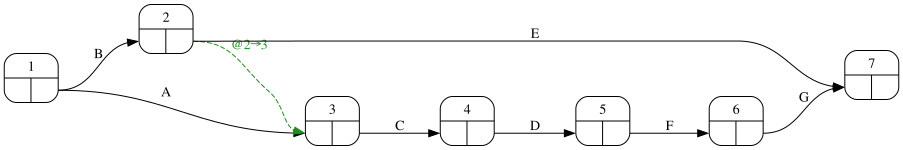

In [9]:
#| fig-cap: "Grafo PERT con los nodos numerados"
#| label: fig-pert
proyecto.pert(durations=False, ranksep=1)

In [10]:
#| tbl-cap: "Arcos del grafo: origen, destino y comprobación i < j"
#| label: tbl-arcos
arcos = pd.DataFrame([{'actividad': d['activity'], 'i': i, 'j': j, 'i < j': i < j}
                      for i, j, d in proyecto.pert_graph.edges(data=True)]).set_index('actividad')
arcos

,i,j,i < j
actividad,,,
B,1,2,True
A,1,3,True
@2→3,2,3,True
E,2,7,True
C,3,4,True
D,4,5,True
F,5,6,True
G,6,7,True


In [11]:
Markdown(f'La numeración de la librería cumple la regla en {int(arcos["i < j"].sum())} de {len(arcos)} arcos.')

La numeración de la librería cumple la regla en 8 de 8 arcos.

## Apartado 2

In [12]:
display(Markdown(pregunta_2))

2. ¿Qué nodos pueden intercambiar su número sin violar la regla? Dé una segunda numeración válida.  

Dos nodos pueden intercambiar su número cuando no hay ningún camino entre ellos (ninguno es antecesor del otro). Se comprueba con el grafo: el par $(u, v)$ es intercambiable si $v$ no es alcanzable desde $u$ ni $u$ desde $v$.

In [13]:
G = proyecto.pert_graph
nodos = sorted(G.nodes)
intercambiables = [(u, v) for u in nodos for v in nodos if u < v
                   and not nx.has_path(G, u, v) and not nx.has_path(G, v, u)]
print('Pares de nodos intercambiables:', intercambiables or 'ninguno')

Pares de nodos intercambiables: ninguno


In [14]:
if intercambiables:
    u, v = intercambiables[0]
    renumerar = {u: v, v: u}
    arcos2 = arcos.copy()
    arcos2['i'] = arcos2['i'].map(lambda x: renumerar.get(x, x)); arcos2['j'] = arcos2['j'].map(lambda x: renumerar.get(x, x))
    arcos2['i < j'] = arcos2['i'] < arcos2['j']
    display(Markdown(f'Intercambiando los nodos {u} y {v} todos los arcos siguen cumpliendo i < j: {bool(arcos2["i < j"].all())}.'))
    display(arcos2)
else:
    display(Markdown('No hay dos nodos intercambiables: la numeración topológica es única.'))

No hay dos nodos intercambiables: la numeración topológica es única.

## Apartado 3

In [15]:
display(Markdown(pregunta_3))

3. ¿Cuántas numeraciones válidas distintas admite el grafo? (Es el número de ordenaciones topológicas; cuéntelas con un programa.)  

Las numeraciones válidas son las ordenaciones topológicas del grafo de sucesos. Se cuentan con programación dinámica sobre subconjuntos: el número de formas de ordenar un conjunto $S$ es la suma, sobre cada nodo $v$ de $S$ sin antecesores dentro de $S$, de las formas de ordenar $S \setminus \{v\}$.

In [16]:
from functools import lru_cache
antecesores = {v: {u for u in nodos if nx.has_path(G, u, v) and u != v} for v in nodos}
@lru_cache(maxsize=None)
def ordenaciones(restantes):
    if not restantes:
        return 1
    S = set(restantes)
    return sum(ordenaciones(tuple(sorted(S - {v}))) for v in S if not (antecesores[v] & S))
n_numeraciones = ordenaciones(tuple(nodos))
Markdown(f'El grafo admite **{n_numeraciones}** numeraciones válidas distintas (una sola si cada nodo es antecesor o descendiente de todos los demás).')

El grafo admite **1** numeraciones válidas distintas (una sola si cada nodo es antecesor o descendiente de todos los demás).

In [17]:
from itertools import islice
print('Tres de ellas (nodo de la librería → nuevo número), generadas con networkx:')
for orden in islice(nx.all_topological_sorts(G), 3):
    print('  ', {viejo: nuevo + 1 for nuevo, viejo in enumerate(orden)})

Tres de ellas (nodo de la librería → nuevo número), generadas con networkx:
   {'1': 1, '2': 2, '3': 3, '4': 4, '5': 5, '6': 6, '7': 7}


## Apartado 4

In [18]:
display(Markdown(pregunta_4))

4. ¿Por qué conviene que la numeración sea creciente a lo largo de los arcos? Piense en la matriz de Zaderenko.  

Con numeración creciente, la matriz de Zaderenko es triangular superior: cada arco está por encima de la diagonal, los tiempos tempranos se calculan recorriendo las columnas de izquierda a derecha y los tardíos las filas de abajo arriba, sin tener que buscar un orden de cálculo. Además, la regla garantiza que no hay ciclos.

In [19]:
#| tbl-cap: "Matriz de Zaderenko (sin duraciones: X marca los arcos)"
#| label: tbl-zaderenko
Z = pd.DataFrame('', index=nodos, columns=nodos)
for i, j, d in G.edges(data=True):
    Z.loc[i, j] = d['activity']
Z

,1,2,3,4,5,6,7
1,,B,A,,,,
2,,,@2→3,,,,E
3,,,,C,,,
4,,,,,D,,
5,,,,,,F,
6,,,,,,,G
7,,,,,,,
